# Deep Q-Network

A neural network estimates four action values from a one-hot grid state. Experience replay and a delayed target network stabilise the bootstrap target.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Replay and target networks

The replay buffer stores environmental termination separately from a training time limit. Targets for a terminal transition use the observed reward alone.

In [2]:
import copy
from collections import deque
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.gridworld import S, A, START, GAMMA, choose, step, policy_report
from gallery.neural import seed_cpu


def train(seed):
    seed_cpu(seed)
    rng = np.random.default_rng(seed)
    state_vectors = torch.eye(S)
    online = nn.Sequential(nn.Linear(S, 48), nn.ReLU(), nn.Linear(48, A))
    target = copy.deepcopy(online).requires_grad_(False)
    opt = torch.optim.Adam(online.parameters(), lr=0.0015)
    memory = deque(maxlen=3500)
    trace = []
    steps = 0
    for episode in range(320):
        state = START
        total = 0.0
        epsilon = max(0.06, 0.8 / (1 + episode / 45))
        for _ in range(60):
            with torch.no_grad():
                action = choose(online(state_vectors[state]).numpy(), epsilon, rng)
            nxt, reward, done = step(state, action, rng)
            memory.append((state, action, reward, nxt, done))
            if len(memory) >= 64 and steps % 2 == 0:
                s, a, r, n, terminal = zip(*random.sample(memory, 48))
                s = torch.tensor(s)
                a = torch.tensor(a)
                r = torch.tensor(r, dtype=torch.float32)
                with torch.no_grad():
                    goal = (
                        r
                        + GAMMA
                        * (~torch.tensor(terminal))
                        * target(state_vectors[list(n)]).max(1).values
                    )
                estimate = online(state_vectors[s]).gather(1, a[:, None]).squeeze(1)
                loss = nn.functional.smooth_l1_loss(estimate, goal)
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(online.parameters(), 2)
                opt.step()
            steps += 1
            if steps % 100 == 0:
                target.load_state_dict(online.state_dict())
            total += reward
            state = nxt
            if done:
                break
        trace.append(total)
    with torch.no_grad():
        policy = online(state_vectors).argmax(1).numpy()
    return policy, trace

## Independent evaluation

Each network is trained from a fresh seed. Evaluation removes exploration and uses the same starting-state protocol as tabular Q-learning.

Seed 17: mean return 0.668, goal 98.3%, pit 1.7%, mean steps 8.5, exact discounted start value 0.416
Seed 29: mean return 0.668, goal 98.3%, pit 1.7%, mean steps 8.5, exact discounted start value 0.416
Seed 53: mean return 0.691, goal 100.0%, pit 0.0%, mean steps 8.7, exact discounted start value 0.413
Random policy: mean return -1.715, goal 15.8%, pit 70.0%, mean steps 30.2
Across training seeds: mean return 0.676, sample SD 0.013


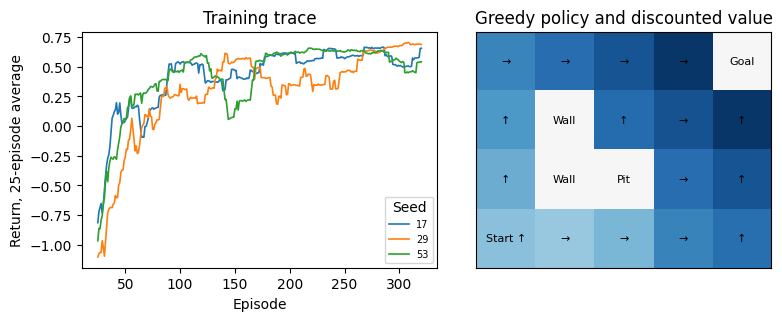

In [3]:
policies, curves = [], []
for seed in (17, 29, 53):
    p, curve = train(seed)
    policies.append((seed, p))
    curves.append(curve)
policy_report(policies, curves, "Return, 25-episode average", "Episode")
plt.show()

## Reading the result

This small-state experiment isolates replay and target updates. Its tabular baseline is available on exactly the same task.

## References

[Mnih et al., Human-level control through deep reinforcement learning (2015)](https://doi.org/10.1038/nature14236)

[Sutton and Barto, Reinforcement Learning: An Introduction (2018)](https://mitpress.mit.edu/9780262039246/reinforcement-learning/)

[Grid dynamics and policy evaluation](../../../gallery/gridworld.py)